# Visualize the learning process

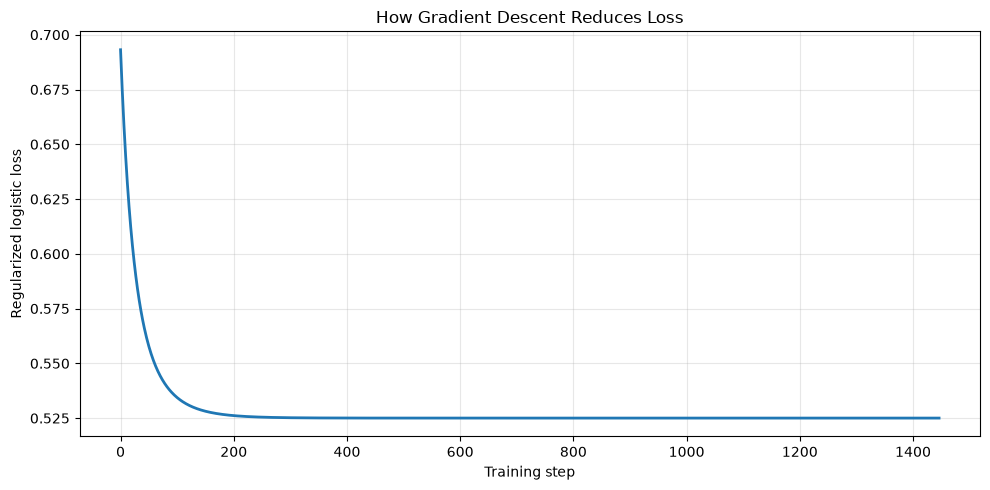

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from logistic import LogisticClassifier

rng = np.random.default_rng(42)

X = rng.normal(size=(500, 2))

true_logits = -0.5 + 1.5 * X[:, 0] - X[:, 1]

probabilities = LogisticClassifier.sigmoid(
    true_logits
)

y = rng.binomial(1, probabilities)

model = LogisticClassifier(
    lr=0.1,
    steps=10000,
    l2=0.01,
    tol=1e-8
)

model.fit(X, y)

plt.figure(figsize=(10, 5))

plt.plot(
    model.loss_history_,
    linewidth=2
)

plt.xlabel("Training step")
plt.ylabel("Regularized logistic loss")
plt.title("How Gradient Descent Reduces Loss")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Compare against scikit-learn defaults

In [2]:
import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression


# Our existing trained classifier
custom_model = model

# Fit scikit-learn using its defaults
sklearn_default = LogisticRegression()

sklearn_default.fit(X, y)

# Compare feature coefficients
coef_gap = np.max(np.abs(custom_model.coef_ - sklearn_default.coef_.ravel()))

# Compare the intercept
intercept_gap = abs(custom_model.intercept_ - sklearn_default.intercept_[0])

# Compare probabilities for the positive class
custom_probs = custom_model.predict_proba(X)

sklearn_probs = sklearn_default.predict_proba(X)[:, 1]

probability_gap = np.max(np.abs(custom_probs - sklearn_probs))

print("Our coefficients:", custom_model.coef_)
print("Sklearn coefficients:", sklearn_default.coef_.ravel())

print("Our intercept:", custom_model.intercept_)
print("Sklearn intercept:", sklearn_default.intercept_[0])

print("Coefficient gap:", coef_gap)
print("Intercept gap:", intercept_gap)
print("Probability gap:", probability_gap)

Our coefficients: [ 1.23382974 -0.86568447]
Sklearn coefficients: [ 1.3522073  -0.95525053]
Our intercept: -0.3823233345059949
Sklearn intercept: -0.3959540788106387
Coefficient gap: 0.1183775595216503
Intercept gap: 0.013630744304643783
Probability gap: 0.026395291225202344


In [3]:
def compare_models(custom, reference, X, stage):

    custom_coef = custom.coef_
    reference_coef = reference.coef_.ravel()

    coef_gap = np.max(np.abs(custom_coef - reference_coef))

    intercept_gap = abs(custom.intercept_ - reference.intercept_[0])

    custom_probs = custom.predict_proba(X)
    reference_probs = reference.predict_proba(X)[:, 1]

    probability_gap = np.max(np.abs(custom_probs - reference_probs))

    return {
        "Stage": stage,
        "Max coefficient gap": coef_gap,
        "Intercept gap": intercept_gap,
        "Max probability gap": probability_gap
    }

In [4]:
n = len(y)

# Translate our L2 strength to sklearn's C
matched_C = 1 / (n * custom_model.l2)

results = []

# Stage 1: Default sklearn settings
results.append(compare_models(custom_model, sklearn_default, X, "1. Default sklearn"))

# Stage 2: Match regularization strength
sklearn_matched = LogisticRegression(C=matched_C, solver="lbfgs", max_iter=1000)

sklearn_matched.fit(X, y)

results.append(compare_models(custom_model, sklearn_matched, X, "2. Matched regularization"))

# Stage 3: Confirm the intercept convention
sklearn_intercept = LogisticRegression(C=matched_C, solver="lbfgs", fit_intercept=True, max_iter=1000)

sklearn_intercept.fit(X, y)

results.append(compare_models(custom_model, sklearn_intercept, X, "3. Intercept convention confirmed"))

# Stage 4: Tighten both solver tolerances
custom_precise = LogisticClassifier(lr=0.1, steps=50000, l2=0.01, tol=1e-11)

custom_precise.fit(X, y)

sklearn_precise = LogisticRegression(C=matched_C, solver="lbfgs", fit_intercept=True, tol=1e-12, max_iter=20000)

sklearn_precise.fit(X, y)

results.append(compare_models(custom_precise, sklearn_precise, X, "4. Tightened tolerances"))

reconciliation_df = pd.DataFrame(results)

display(reconciliation_df)

print("Matched C:", matched_C)
print("Custom convergence step:", custom_precise.converged_at)
print("Sklearn iterations:", sklearn_precise.n_iter_)

,Stage,Max coefficient gap,Intercept gap,Max probability gap
0,1. Default sklearn,1.183776e-01,1.363074e-02,2.639529e-02
1,2. Matched regularization,4.238989e-05,6.167160e-06,3.544558e-05
2,3. Intercept convention confirmed,4.238989e-05,6.167160e-06,3.544558e-05
3,4. Tightened tolerances,5.017710e-10,8.265931e-10,5.870741e-10


Matched C: 0.2
Custom convergence step: 2192
Sklearn iterations: [8]


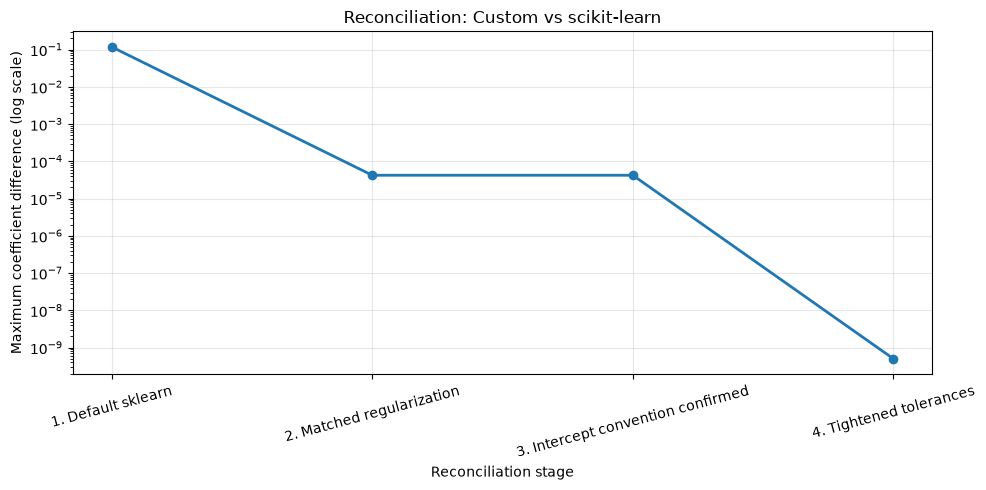

In [5]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))
plt.plot(reconciliation_df["Stage"], reconciliation_df["Max coefficient gap"], marker="o", linewidth=2)
plt.yscale("log")
plt.xlabel("Reconciliation stage")
plt.ylabel("Maximum coefficient difference (log scale)")
plt.title("Reconciliation: Custom vs scikit-learn")
plt.xticks(rotation=15)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

# Part 2 — Real-World Imbalanced Classification

In [6]:
import pandas as pd
import numpy as np

bank_df = pd.read_csv("data/bank-additional-full.csv", sep=";")
bank_df.head(5)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [7]:
#Convert yes/no decision into 1 and 0 label
y_bank = bank_df["y"].map({"no": 0, "yes": 1})

#Exclude the outcome and call duration
X_bank = bank_df.drop(columns=["y", "duration"])

#Verify that our label are valid
assert y_bank.notna().all()

# Count examples and input features
n_rows, n_features = X_bank.shape

positive_rate = y_bank.mean()
negative_rate = 1 - positive_rate

print("Observations:", n_rows)
print("Input features:", n_features)
print("Positive rate:", positive_rate)
print("Negative rate:", negative_rate)

print(
    "Always-negative accuracy:",
    negative_rate
)

assert n_rows >= 2000
assert n_features >= 6
assert positive_rate < 0.20

Observations: 41188
Input features: 19
Positive rate: 0.11265417111780131
Negative rate: 0.8873458288821987
Always-negative accuracy: 0.8873458288821987


In [8]:
from sklearn.model_selection import train_test_split

# First: reserve 20% for the final test
X_dev, X_test_bank, y_dev, y_test_bank = train_test_split(X_bank, y_bank, test_size=0.2, random_state=42, stratify=y_bank)

# Second: reserve 25% of the remaining 80%
# This equals 20% of the original dataset
X_train_bank, X_val_bank, y_train_bank, y_val_bank = train_test_split(X_dev, y_dev, test_size=0.25, random_state=42, stratify=y_dev)

#Check the results
for name, labels in [("Training", y_train_bank), ("Validation", y_val_bank), ("Test", y_test_bank)]:

    print(f"{name} : {len(labels)} rows, "
          f"positive rate : {labels.mean():.2%}%")

Training : 24712 rows, positive rate : 11.27%%
Validation : 8238 rows, positive rate : 11.26%%
Test : 8238 rows, positive rate : 11.26%%


## Part 3 — Preprocessing and Baseline Classification

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

#Identify numerical and categorical columns in dataframe
numeric_columns = X_train_bank.select_dtypes(include=["number"]).columns.to_list()

categorical_columns = X_train_bank.select_dtypes(exclude=["number"]).columns.to_list()

#Prepare numerical features
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

#Prepare categorical features
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

#Combiner both preprocessing branches
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

print("Numerical features:", numeric_columns)
print("Categorical features:", categorical_columns)

Numerical features: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone

#Model A: Ordinary Logistic Regression 
unweighted_pipeline = Pipeline([
    ("pre", clone(preprocessor)),
    ("classifier", LogisticRegression(C=1.0, solver="lbfgs", max_iter=3000))
])

#Model B: Balanced class weights
weighted_pipeline = Pipeline([
    ("pre", clone(preprocessor)),
    ("classifier", LogisticRegression(C=1.0, class_weight="balanced", solver="lbfgs", max_iter=3000))
])

#Train both models
unweighted_pipeline.fit(X_train_bank, y_train_bank)

weighted_pipeline.fit(X_train_bank, y_train_bank)

print("Both classification models fitted successfully.")

print("Unweighted iterations:", unweighted_pipeline.named_steps["classifier"].n_iter_)

print("Balanced iterations:", weighted_pipeline.named_steps["classifier"].n_iter_)

Both classification models fitted successfully.
Unweighted iterations: [60]
Balanced iterations: [78]


In [11]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, log_loss

def evaluate_classifier(name, y_true, probabilities, threshold=0.5):

    predictions = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_true, predictions, labels=[0,1]).ravel()

    specificity = (tn / (tn + fp) if (tn + fp) > 0 else 0.0)

    return {
        "Model": name,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "Specificity": specificity,
        "F1": f1_score(y_true, predictions, zero_division=0),
        "Log-loss": log_loss(y_true, probabilities, labels=[0,1]) 
    }

In [12]:
# Predict probabilities on validation data

unweighted_val_probs = unweighted_pipeline.predict_proba(X_val_bank)[:,1]

weighted_val_probs = weighted_pipeline.predict_proba(X_val_bank)[:,1]

# Baseline: predict training prevalence for everyone
train_positive_rate = y_train_bank.mean()

baseline_val_probs = np.full(len(y_val_bank), train_positive_rate)

# Evaluate all three
validation_results = pd.DataFrame([
    evaluate_classifier("Base-rate baseline", y_val_bank, baseline_val_probs),
    evaluate_classifier("Unweighted logistic", y_val_bank, unweighted_val_probs),
    evaluate_classifier("Balanced logistic", y_val_bank, weighted_val_probs)
])

display(validation_results.round(4))

print("Training positive rate:", f"{train_positive_rate:.2%}")

print("Validation positive rate:",f"{y_val_bank.mean():.2%}")

,Model,TN,FP,FN,TP,Precision,Recall,Specificity,F1,Log-loss
0,Base-rate baseline,7310,0,928,0,0.0000,0.0000,1.0000,0.0000,0.3520
1,Unweighted logistic,7195,115,714,214,0.6505,0.2306,0.9843,0.3405,0.2777
2,Balanced logistic,6232,1078,347,581,0.3502,0.6261,0.8525,0.4492,0.5260


Training positive rate: 11.27%
Validation positive rate: 11.26%


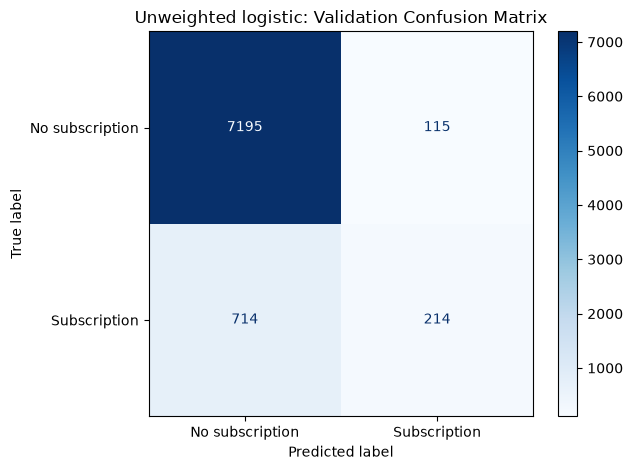

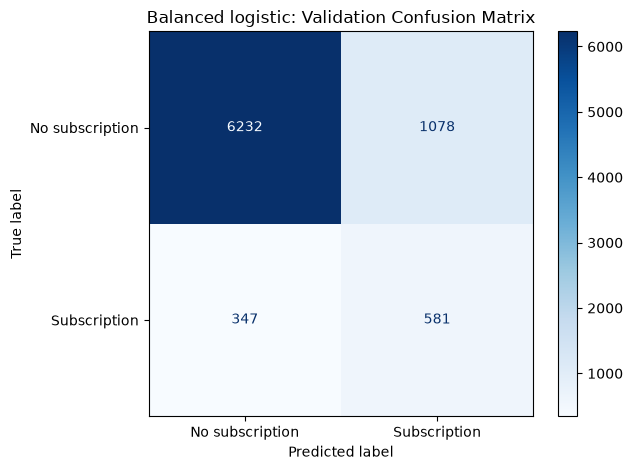

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay


for name, probabilities in [
    ("Unweighted logistic", unweighted_val_probs),
    ("Balanced logistic", weighted_val_probs)
]:

    predictions = (probabilities >= 0.5).astype(int)

    ConfusionMatrixDisplay.from_predictions(
        y_val_bank,
        predictions,
        labels=[0, 1],
        display_labels=["No subscription", "Subscription"],
        cmap="Blues",
        values_format="d"
    )

    plt.title(f"{name}: Validation Confusion Matrix")
    plt.tight_layout()
    plt.show()

In [14]:
#Define the calibration function

def calibration_table(y_true, probabilities, n_bins=10):

    y_true = np.asarray(y_true)
    probabilities = np.asarray(probabilities)

    # Define the bucket boundaries
    edges = np.linspace(0, 1, n_bins + 1)

    # Assign each prediction to a bucket
    bucket_ids = np.digitize(probabilities,edges[1:-1])

    # Collect the data in a DataFrame
    data = pd.DataFrame({
        "actual": y_true,
        "predicted": probabilities,
        "bucket": bucket_ids
    })

    rows = []

    # Calculate statistics for each bucket
    for bucket in range(n_bins):

        subset = data[data["bucket"] == bucket]
        count = len(subset)

        if count == 0:
            rows.append({
                "Bucket": bucket + 1,
                "Range": (
                    f"{edges[bucket]:.0%}–"
                    f"{edges[bucket + 1]:.0%}"
                ),
                "Count": 0,
                "Mean predicted": np.nan,
                "Observed rate": np.nan,
                "Calibration gap": np.nan
            })
            continue

        mean_predicted = subset["predicted"].mean()
        observed_rate = subset["actual"].mean()

        gap = abs(mean_predicted - observed_rate)

        rows.append({
            "Bucket": bucket + 1,
            "Range": (
                f"{edges[bucket]:.0%}–"
                f"{edges[bucket + 1]:.0%}"
            ),
            "Count": count,
            "Mean predicted": mean_predicted,
            "Observed rate": observed_rate,
            "Calibration gap": gap
        })

    return pd.DataFrame(rows)

In [15]:
#Calculate calibration tables and ECE

def expected_calibration_error(table):

    total = table["Count"].sum()

    weighted_gaps = (
        table["Count"] * table["Calibration gap"]
    )

    return weighted_gaps.sum() / total


# Build both validation calibration tables
unweighted_calibration = calibration_table(
    y_val_bank,
    unweighted_val_probs,
    n_bins=10
)

weighted_calibration = calibration_table(
    y_val_bank,
    weighted_val_probs,
    n_bins=10
)

# Calculate ECE values
unweighted_ece = expected_calibration_error(
    unweighted_calibration
)

weighted_ece = expected_calibration_error(
    weighted_calibration
)

print("UNWEIGHTED CALIBRATION")
display(unweighted_calibration.round(4))

print("BALANCED CALIBRATION")
display(weighted_calibration.round(4))

print(f"Unweighted ECE: {unweighted_ece:.4f}")
print(f"Balanced ECE: {weighted_ece:.4f}")

# Confirm that both tables cover all validation rows
assert unweighted_calibration["Count"].sum() == len(y_val_bank)
assert weighted_calibration["Count"].sum() == len(y_val_bank)

# Confirm valid ECE values
assert 0 <= unweighted_ece <= 1
assert 0 <= weighted_ece <= 1

UNWEIGHTED CALIBRATION


,Bucket,Range,Count,Mean predicted,Observed rate,Calibration gap
0,1,0%–10%,6316,0.0520,0.0515,0.0006
1,2,10%–20%,713,0.1372,0.1220,0.0152
2,3,20%–30%,348,0.2418,0.2931,0.0513
3,4,30%–40%,323,0.3507,0.3406,0.0102
4,5,40%–50%,209,0.4444,0.4306,0.0138
5,6,50%–60%,80,0.5456,0.4625,0.0831
6,7,60%–70%,109,0.6513,0.6606,0.0093
7,8,70%–80%,89,0.7418,0.7640,0.0222
8,9,80%–90%,51,0.8392,0.7255,0.1137
9,10,90%–100%,0,NaN,NaN,NaN


BALANCED CALIBRATION


,Bucket,Range,Count,Mean predicted,Observed rate,Calibration gap
0,1,0%–10%,2,0.0712,0.0000,0.0712
1,2,10%–20%,623,0.1780,0.0177,0.1604
2,3,20%–30%,2747,0.2498,0.0415,0.2083
3,4,30%–40%,2421,0.3442,0.0653,0.2789
4,5,40%–50%,786,0.4443,0.0814,0.3629
5,6,50%–60%,256,0.5414,0.1172,0.4242
6,7,60%–70%,365,0.6546,0.2192,0.4354
7,8,70%–80%,293,0.7595,0.3481,0.4114
8,9,80%–90%,434,0.8462,0.3871,0.4591
9,10,90%–100%,311,0.9447,0.6463,0.2984


Unweighted ECE: 0.0065
Balanced ECE: 0.2807


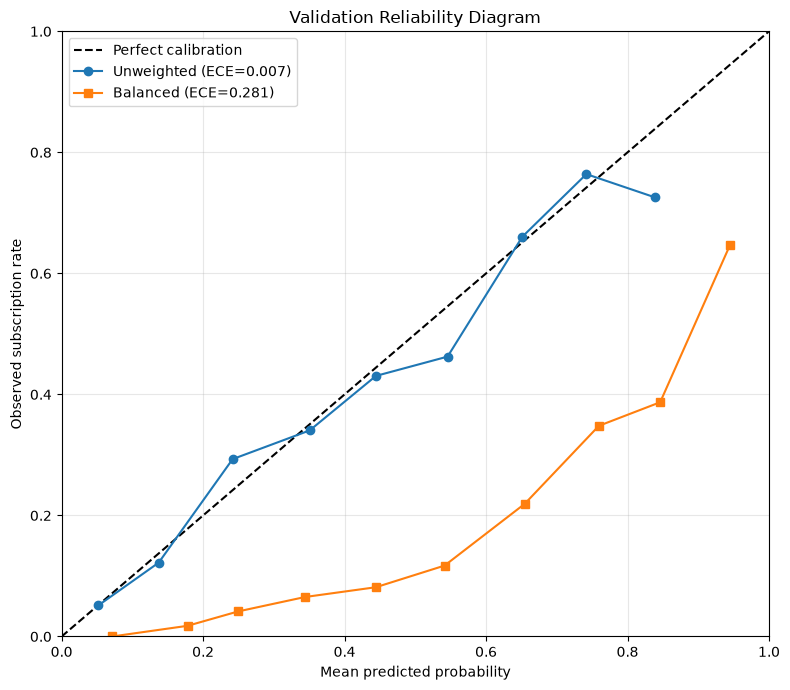

In [16]:
import matplotlib.pyplot as plt


plt.figure(figsize=(8, 7))

# Perfect calibration reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="black",
    label="Perfect calibration"
)

# Unweighted reliability curve
plt.plot(
    unweighted_calibration["Mean predicted"],
    unweighted_calibration["Observed rate"],
    marker="o",
    label=f"Unweighted (ECE={unweighted_ece:.3f})"
)

# Balanced reliability curve
plt.plot(
    weighted_calibration["Mean predicted"],
    weighted_calibration["Observed rate"],
    marker="s",
    label=f"Balanced (ECE={weighted_ece:.3f})"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Observed subscription rate")
plt.title("Validation Reliability Diagram")

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

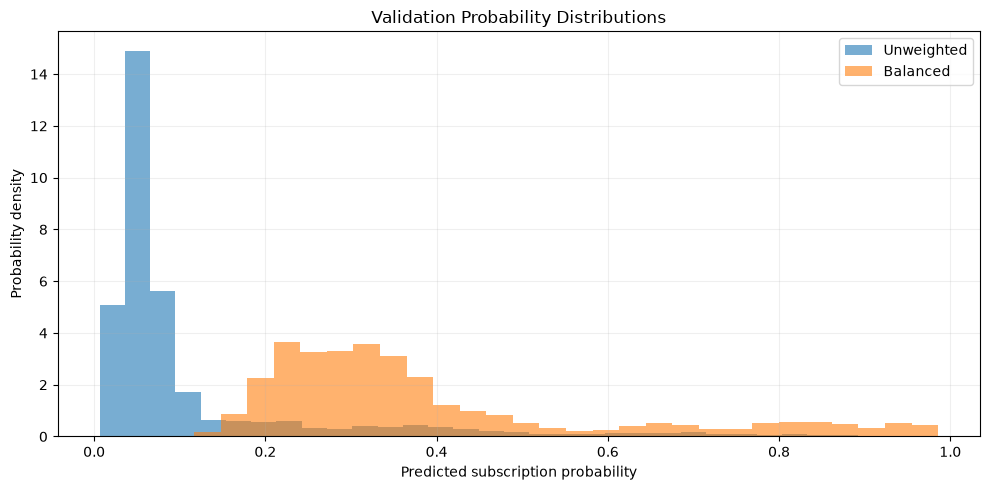

Mean unweighted probability: 0.11412448469487313
Mean balanced probability: 0.393379319171406
Actual validation positive rate: 0.11264870114105366


In [17]:
plt.figure(figsize=(10, 5))

plt.hist(
    unweighted_val_probs,
    bins=30,
    alpha=0.6,
    label="Unweighted",
    density=True
)

plt.hist(
    weighted_val_probs,
    bins=30,
    alpha=0.6,
    label="Balanced",
    density=True
)

plt.xlabel("Predicted subscription probability")
plt.ylabel("Probability density")
plt.title("Validation Probability Distributions")

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print(
    "Mean unweighted probability:",
    unweighted_val_probs.mean()
)

print(
    "Mean balanced probability:",
    weighted_val_probs.mean()
)

print(
    "Actual validation positive rate:",
    y_val_bank.mean()
)

In [18]:
from sklearn.metrics import confusion_matrix

# Our fixed, hypothetical operational costs
COST_FP = 2
COST_FN = 15


def calculate_decision_cost(y_true, probabilities, threshold):

    predictions = (
        np.asarray(probabilities) >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    total_cost = (
        COST_FP * fp
        + COST_FN * fn
    )

    return {
        "Threshold": threshold,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Flagged": fp + tp,
        "Total cost (€)": total_cost,
        "Cost per customer (€)": total_cost / len(y_true)
    }

In [19]:
theoretical_threshold = COST_FP / (COST_FP + COST_FN)

default_result = calculate_decision_cost(
    y_val_bank,
    unweighted_val_probs,
    threshold=0.5
)

theoretical_result = calculate_decision_cost(
    y_val_bank,
    unweighted_val_probs,
    threshold=theoretical_threshold
)

initial_threshold_comparison = pd.DataFrame([
    default_result,
    theoretical_result
])

display(initial_threshold_comparison.round(4))

print(
    "Theoretical threshold:",
    f"{theoretical_threshold:.4f}"
)

,Threshold,TN,FP,FN,TP,Flagged,Total cost (€),Cost per customer (€)
0,0.5000,7195,115,714,214,329,10940,1.3280
1,0.1176,6236,1074,348,580,1654,7368,0.8944


Theoretical threshold: 0.1176


In [20]:
# Every distinct probability is a possible decision boundary
thresholds = np.unique(
    np.concatenate([
        [0.0],
        unweighted_val_probs,
        [1.0]
    ])
)

sweep_results = []

for threshold in thresholds:

    result = calculate_decision_cost(
        y_val_bank,
        unweighted_val_probs,
        threshold=threshold
    )

    sweep_results.append(result)

threshold_sweep = pd.DataFrame(sweep_results)

# Find the minimum observed validation cost
minimum_cost = threshold_sweep["Total cost (€)"].min()

# Keep all thresholds tied at that minimum
minimum_rows = threshold_sweep[
    threshold_sweep["Total cost (€)"] == minimum_cost
]

# Deterministic tie-break: prefer the threshold
# nearest to the theory-derived threshold
closest_index = (
    (minimum_rows["Threshold"] - theoretical_threshold)
    .abs()
    .idxmin()
)

selected_row = minimum_rows.loc[closest_index]

validation_optimal_threshold = float(
    selected_row["Threshold"]
)

print("Number of thresholds evaluated:", len(threshold_sweep))
print("Lowest validation cost (€):", minimum_cost)
print("Validation-selected threshold:", validation_optimal_threshold)

display(
    pd.DataFrame([
        default_result,
        theoretical_result,
        selected_row.to_dict()
    ]).round(4)
)

Number of thresholds evaluated: 8147
Lowest validation cost (€): 7319
Validation-selected threshold: 0.11495847265893767


,Threshold,TN,FP,FN,TP,Flagged,Total cost (€),Cost per customer (€)
0,0.5000,7195.0,115.0,714.0,214.0,329.0,10940.0,1.3280
1,0.1176,6236.0,1074.0,348.0,580.0,1654.0,7368.0,0.8944
2,0.1150,6208.0,1102.0,341.0,587.0,1689.0,7319.0,0.8884


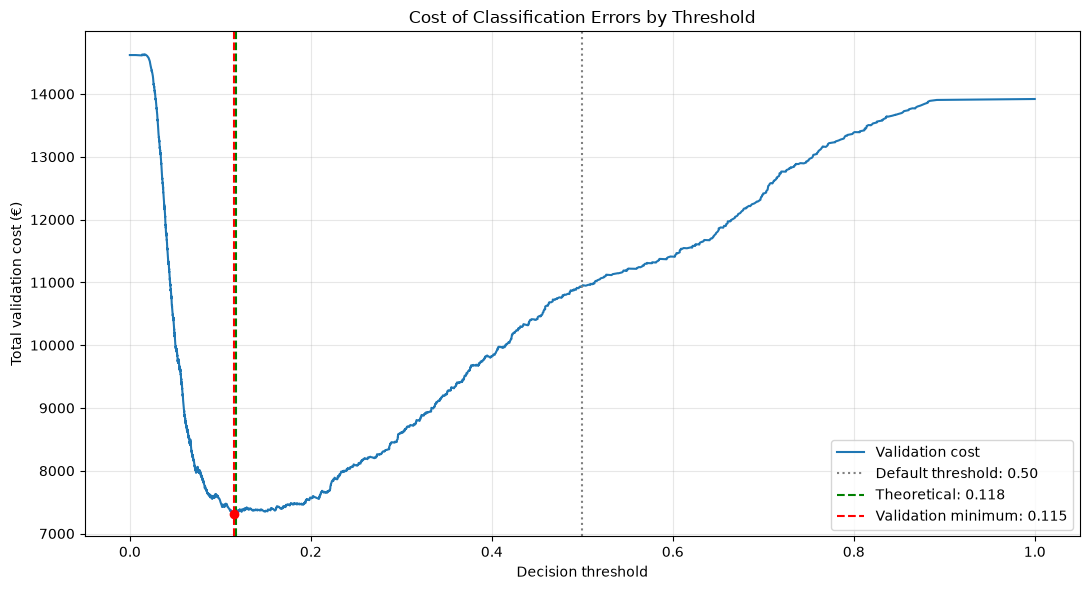

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

plt.plot(
    threshold_sweep["Threshold"],
    threshold_sweep["Total cost (€)"],
    linewidth=1.5,
    label="Validation cost"
)

plt.axvline(
    0.5,
    color="gray",
    linestyle=":",
    label="Default threshold: 0.50"
)

plt.axvline(
    theoretical_threshold,
    color="green",
    linestyle="--",
    label=f"Theoretical: {theoretical_threshold:.3f}"
)

plt.axvline(
    validation_optimal_threshold,
    color="red",
    linestyle="--",
    label=f"Validation minimum: {validation_optimal_threshold:.3f}"
)

plt.scatter(
    [validation_optimal_threshold],
    [minimum_cost],
    color="red",
    zorder=5
)

plt.xlabel("Decision threshold")
plt.ylabel("Total validation cost (€)")
plt.title("Cost of Classification Errors by Threshold")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
near_minimum = threshold_sweep[
    threshold_sweep["Total cost (€)"] <= minimum_cost * 1.01
]

lower_threshold = near_minimum["Threshold"].min()
upper_threshold = near_minimum["Threshold"].max()

print("Minimum validation cost (€):", minimum_cost)

print(
    "Thresholds within 1% of minimum:",
    f"{lower_threshold:.4f} to {upper_threshold:.4f}"
)

print(
    "Number of candidate thresholds in this range:",
    len(near_minimum)
)

theoretical_extra_cost = (
    theoretical_result["Total cost (€)"] - minimum_cost
)

print(
    "Extra validation cost at theoretical threshold (€):",
    theoretical_extra_cost
)

Minimum validation cost (€): 7319
Thresholds within 1% of minimum: 0.1098 to 0.1614
Number of candidate thresholds in this range: 300
Extra validation cost at theoretical threshold (€): 49


In [23]:
# Use the cost assumptions declared before threshold tuning
LOCKED_COST_FP = COST_FP
LOCKED_COST_FN = COST_FN

# Primary operating threshold: determined by the cost formula
locked_primary_threshold = (
    LOCKED_COST_FP / (LOCKED_COST_FP + LOCKED_COST_FN)
)

# Alternative: selected using validation data only
locked_validation_threshold = float(
    validation_optimal_threshold
)

# Default threshold for comparison
locked_default_threshold = 0.50

print("Primary threshold:", locked_primary_threshold)
print("Validation-selected threshold:", locked_validation_threshold)
print("Default threshold:", locked_default_threshold)

assert np.isclose(locked_primary_threshold, 2 / 17)
assert 0 <= locked_validation_threshold <= 1

Primary threshold: 0.11764705882352941
Validation-selected threshold: 0.11495847265893767
Default threshold: 0.5


In [24]:
# The models are already fitted: do not call fit() again

unweighted_test_probs = (
    unweighted_pipeline.predict_proba(X_test_bank)[:, 1]
)

balanced_test_probs = (
    weighted_pipeline.predict_proba(X_test_bank)[:, 1]
)

# Baseline probability comes from training prevalence
baseline_test_probs = np.full(
    len(y_test_bank),
    y_train_bank.mean()
)

print("Test observations:", len(y_test_bank))
print("Actual positive rate:", f"{y_test_bank.mean():.2%}")

print(
    "Mean unweighted probability:",
    unweighted_test_probs.mean()
)

print(
    "Mean balanced probability:",
    balanced_test_probs.mean()
)

assert len(unweighted_test_probs) == len(y_test_bank)
assert len(balanced_test_probs) == len(y_test_bank)
assert np.isfinite(unweighted_test_probs).all()
assert np.isfinite(balanced_test_probs).all()

Test observations: 8238
Actual positive rate: 11.26%
Mean unweighted probability: 0.1120141544532987
Mean balanced probability: 0.3911395334463786


In [25]:
test_rules = [
    ("Unweighted at 0.50",
     unweighted_test_probs,
     locked_default_threshold),

    ("Unweighted, theoretical",
     unweighted_test_probs,
     locked_primary_threshold),

    ("Unweighted, validation-selected",
     unweighted_test_probs,
     locked_validation_threshold),

    ("Balanced at 0.50",
     balanced_test_probs,
     locked_default_threshold)
]

final_rows = []

for name, probabilities, threshold in test_rules:

    classification = evaluate_classifier(
        name,
        y_test_bank,
        probabilities,
        threshold=threshold
    )

    costs = calculate_decision_cost(
        y_test_bank,
        probabilities,
        threshold=threshold
    )

    classification.update({
        "Threshold": threshold,
        "Flagged": costs["Flagged"],
        "Total cost (€)": costs["Total cost (€)"],
        "Cost per customer (€)": costs["Cost per customer (€)"]
    })

    final_rows.append(classification)

final_test_results = pd.DataFrame(final_rows)

display(final_test_results.round(4))

# Independent base-rate log-loss for comparison
baseline_test_logloss = log_loss(
    y_test_bank,
    baseline_test_probs,
    labels=[0, 1]
)

print("Base-rate test log-loss:", baseline_test_logloss)

,Model,TN,FP,FN,TP,Precision,Recall,Specificity,F1,Log-loss,Threshold,Flagged,Total cost (€),Cost per customer (€)
0,Unweighted at 0.50,7213,97,711,217,0.6911,0.2338,0.9867,0.3494,0.2717,0.5000,314,10859,1.3182
1,"Unweighted, theoretical",6273,1037,326,602,0.3673,0.6487,0.8581,0.4690,0.2717,0.1176,1639,6964,0.8454
2,"Unweighted, validation-selected",6246,1064,321,607,0.3633,0.6541,0.8544,0.4671,0.2717,0.1150,1671,6943,0.8428
3,Balanced at 0.50,6269,1041,326,602,0.3664,0.6487,0.8576,0.4683,0.5155,0.5000,1643,6972,0.8463


Base-rate test log-loss: 0.3520175041344016


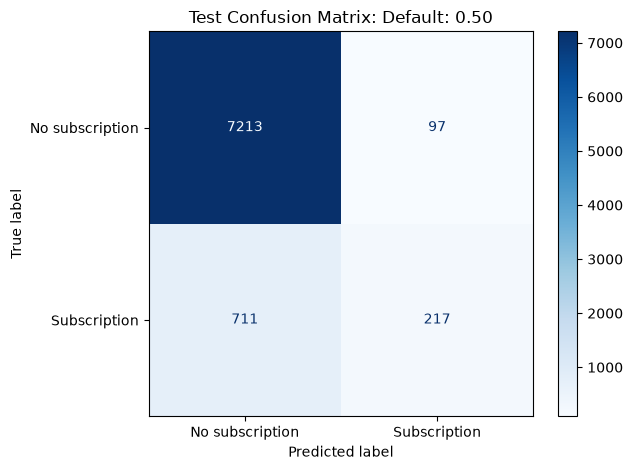

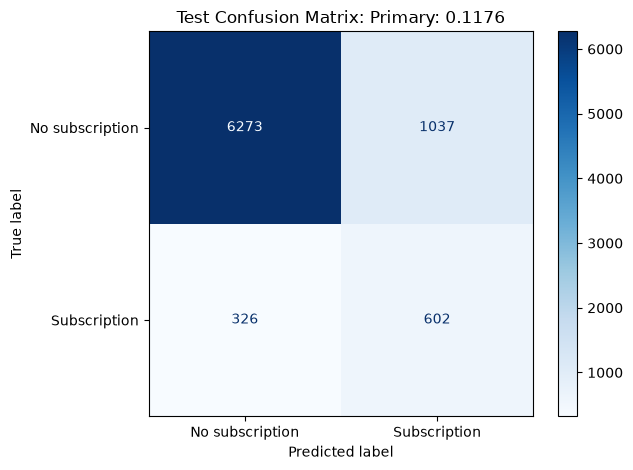

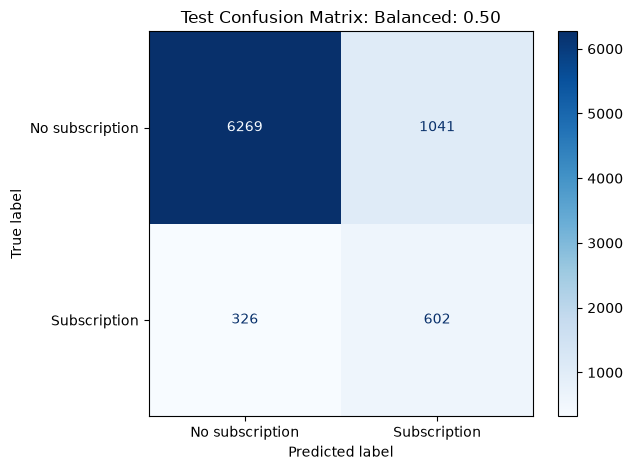

In [26]:
from sklearn.metrics import ConfusionMatrixDisplay

rules_to_plot = [
    ("Default: 0.50",
     unweighted_test_probs,
     locked_default_threshold),

    ("Primary: 0.1176",
     unweighted_test_probs,
     locked_primary_threshold),

    ("Balanced: 0.50",
     balanced_test_probs,
     locked_default_threshold)
]

for name, probabilities, threshold in rules_to_plot:

    predicted_labels = (
        probabilities >= threshold
    ).astype(int)

    ConfusionMatrixDisplay.from_predictions(
        y_test_bank,
        predicted_labels,
        labels=[0, 1],
        display_labels=["No subscription", "Subscription"],
        cmap="Blues",
        values_format="d"
    )

    plt.title(f"Test Confusion Matrix: {name}")
    plt.tight_layout()
    plt.show()

In [27]:
test_unweighted_calibration = calibration_table(
    y_test_bank,
    unweighted_test_probs,
    n_bins=10
)

test_balanced_calibration = calibration_table(
    y_test_bank,
    balanced_test_probs,
    n_bins=10
)

test_unweighted_ece = expected_calibration_error(
    test_unweighted_calibration
)

test_balanced_ece = expected_calibration_error(
    test_balanced_calibration
)

final_calibration_summary = pd.DataFrame({
    "Model": ["Unweighted", "Balanced"],
    "Validation ECE": [
        unweighted_ece,
        weighted_ece
    ],
    "Test ECE": [
        test_unweighted_ece,
        test_balanced_ece
    ],
    "Test log-loss": [
        log_loss(y_test_bank, unweighted_test_probs),
        log_loss(y_test_bank, balanced_test_probs)
    ]
})

display(final_calibration_summary.round(4))

print("\nTEST: UNWEIGHTED CALIBRATION")
display(test_unweighted_calibration.round(4))

print("\nTEST: BALANCED CALIBRATION")
display(test_balanced_calibration.round(4))

,Model,Validation ECE,Test ECE,Test log-loss
0,Unweighted,0.0065,0.0152,0.2717
1,Balanced,0.2807,0.2785,0.5155



TEST: UNWEIGHTED CALIBRATION


,Bucket,Range,Count,Mean predicted,Observed rate,Calibration gap
0,1,0%–10%,6341,0.0521,0.0472,0.0049
1,2,10%–20%,677,0.1365,0.1137,0.0228
2,3,20%–30%,414,0.2436,0.3333,0.0897
3,4,30%–40%,299,0.3475,0.4013,0.0539
4,5,40%–50%,193,0.4366,0.3990,0.0377
5,6,50%–60%,95,0.5512,0.5579,0.0066
6,7,60%–70%,93,0.6507,0.7204,0.0698
7,8,70%–80%,74,0.7354,0.7973,0.0619
8,9,80%–90%,51,0.8441,0.7255,0.1186
9,10,90%–100%,1,0.9027,1.0000,0.0973



TEST: BALANCED CALIBRATION


,Bucket,Range,Count,Mean predicted,Observed rate,Calibration gap
0,1,0%–10%,6,0.0795,0.0000,0.0795
1,2,10%–20%,676,0.1775,0.0370,0.1405
2,3,20%–30%,2723,0.2499,0.0382,0.2117
3,4,30%–40%,2345,0.3429,0.0520,0.2909
4,5,40%–50%,845,0.4435,0.0888,0.3548
5,6,50%–60%,255,0.5439,0.0941,0.4498
6,7,60%–70%,359,0.6562,0.2563,0.4000
7,8,70%–80%,340,0.7570,0.3588,0.3982
8,9,80%–90%,402,0.8451,0.3980,0.4471
9,10,90%–100%,287,0.9443,0.7108,0.2335


In [28]:
# Retrieve rows from our final test table
default_row = final_test_results.loc[
    final_test_results["Model"] == "Unweighted at 0.50"
].iloc[0]

primary_row = final_test_results.loc[
    final_test_results["Model"] == "Unweighted, theoretical"
].iloc[0]


# Calculate changes caused by the lower threshold
extra_flagged = (
    primary_row["Flagged"] - default_row["Flagged"]
)

extra_subscribers_found = (
    primary_row["TP"] - default_row["TP"]
)

extra_false_positives = (
    primary_row["FP"] - default_row["FP"]
)

cost_saved = (
    default_row["Total cost (€)"]
    - primary_row["Total cost (€)"]
)

cost_reduction_pct = (
    cost_saved / default_row["Total cost (€)"] * 100
)


print("Additional customers flagged:", extra_flagged)
print("Additional subscribers identified:", extra_subscribers_found)
print("Additional false positives:", extra_false_positives)
print("Assumed cost saved (€):", cost_saved)
print("Cost reduction (%):", round(cost_reduction_pct, 2))

Additional customers flagged: 1325
Additional subscribers identified: 385
Additional false positives: 940
Assumed cost saved (€): 3895
Cost reduction (%): 35.87


In [29]:
# Keep exactly the three strategies required by R7
strategy_names = [
    "Unweighted at 0.50",
    "Balanced at 0.50",
    "Unweighted, validation-selected"
]

strategy_comparison = final_test_results.loc[
    final_test_results["Model"].isin(strategy_names)
].copy()

# Add the relevant probability calibration result
strategy_comparison["ECE"] = strategy_comparison["Model"].map({
    "Unweighted at 0.50": test_unweighted_ece,
    "Balanced at 0.50": test_balanced_ece,
    "Unweighted, validation-selected": test_unweighted_ece
})

# Select the report-ready columns
strategy_comparison = strategy_comparison[
    [
        "Model",
        "Threshold",
        "Precision",
        "Recall",
        "F1",
        "Log-loss",
        "ECE",
        "Total cost (€)"
    ]
]

display(strategy_comparison.round(4))

,Model,Threshold,Precision,Recall,F1,Log-loss,ECE,Total cost (€)
0,Unweighted at 0.50,0.500,0.6911,0.2338,0.3494,0.2717,0.0152,10859
2,"Unweighted, validation-selected",0.115,0.3633,0.6541,0.4671,0.2717,0.0152,6943
3,Balanced at 0.50,0.500,0.3664,0.6487,0.4683,0.5155,0.2785,6972


In [30]:
from pathlib import Path

# Create a folder for outputs
output_dir = Path("outputs")

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

# Save the final test results
final_test_results.to_csv(
    output_dir / "final_test_results.csv",
    index=False
)

# Save the three-strategy comparison
strategy_comparison.to_csv(
    output_dir / "strategy_comparison.csv",
    index=False
)

# Save the threshold search
threshold_sweep.to_csv(
    output_dir / "validation_threshold_sweep.csv",
    index=False
)

# Save calibration tables
test_unweighted_calibration.to_csv(
    output_dir / "test_unweighted_calibration.csv",
    index=False
)

test_balanced_calibration.to_csv(
    output_dir / "test_balanced_calibration.csv",
    index=False
)

print("Saved results to:", output_dir.resolve())

Saved results to: /Users/adilbegg/mlbatch1/week06/outputs
